# Absenteeism Prediction - Phase 3: Model Comparison

**Question:** given a reported absence, will it be a **long absence (8+ hours)**? Which algorithm and which inputs answer that best **for employees the model has never seen**?

**Rules of this notebook**
* Only the 575 training rows (27 employees) are used. The 6 held-out test employees are not touched.
* Every score comes from employee-grouped cross-validation (5 folds x 5 repeats = 25 validation folds).
* Every number shown was produced by running this notebook. Nothing is copied from elsewhere.

**Contents**
1. [Setup](#1)
2. [How the comparison is designed](#2)
3. [The algorithms in plain language](#3)
4. [Experiment 1: all algorithms on the 13 Phase-2 features](#4)
5. [Experiment 2: random vs grouped validation](#5)
6. [Experiment 3: which features actually help?](#6)
7. [Experiment 4: what if the rule rows had been kept?](#7)
8. [Experiment 5: all algorithms on a reduced feature set](#8)
9. [Experiment 6: hyperparameter tuning (nested CV)](#9)
10. [Experiment 7: confirmation on fresh folds](#10)
11. [Summary, trade-offs and decisions](#11)

<a id='1'></a>
## 1. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(PROJECT_ROOT))

from src import config
from src.data_loader import load_raw_data, build_modelling_dataset, add_target
from src.splitting import group_holdout_split
from src.models import get_candidate_models, make_pipeline
from src.preprocessing import build_preprocessor
from src.evaluate import (cross_validate, summarize, nested_cv_tuning, paired_difference,
                          METRIC_NAMES)

sns.set_theme(style="whitegrid")
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR = config.PROJECT_ROOT / "reports" / "tables"
TABLES_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(config.FIGURES_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

def mean_table(results_by_name, metrics=("pr_auc", "recall", "f1", "precision", "balanced_acc", "accuracy")):
    """Mean of each metric across folds, one row per model (numeric, for sorting/plotting)."""
    return pd.DataFrame({n: r[list(metrics)].mean() for n, r in results_by_name.items()}).T

In [2]:
raw = load_raw_data()
# extra_columns carries the two "period" columns for the ablation only; rows/order are unchanged.
model_df = build_modelling_dataset(raw, extra_columns=config.PERIOD_FEATURES)

# The held-out test employees are set aside here and NEVER used in this notebook.
train_df, _held_out_test = group_holdout_split(model_df)
del _held_out_test

y_train = train_df[config.TARGET_COLUMN]
groups = train_df[config.GROUP_COLUMN]
X_full = train_df[config.FEATURE_COLUMNS]          # the 13 Phase-2 features

SEEDS = (0, 1, 2, 3, 4)                            # 5 folds x 5 repeats = 25 validation folds
print("Training data:", train_df.shape, "| employees:", groups.nunique(),
      f"| long-absence share: {y_train.mean():.3f}")

Training data: (575, 17) | employees: 27 | long-absence share: 0.390


<a id='2'></a>
## 2. How the comparison is designed

**Validation.** Each fold holds out whole employees (`StratifiedGroupKFold`), so the score answers *"how well does the model do for a new employee?"*. Repeating with 5 different random seeds avoids relying on one lucky split. The 25 fold scores are **not independent** (they reuse the same 27 employees), so averages are useful but differences should be read with caution.

**Metrics** (positive class = long absence):

| Metric | Meaning | Role here |
|---|---|---|
| **PR-AUC** | How well the model *ranks* long absences above short ones, focused on the long class | **Main selection metric** (threshold-free, ignores the easy negatives) |
| **Recall** | Share of truly long absences that the model catches | Key operational metric: **a missed long absence is the costly error** (no cover planned) |
| Precision | Share of "long" warnings that are right | A false alarm costs some unnecessary cover planning, which is a smaller harm |
| F1 | Balance of precision and recall | Summary at the default 0.5 threshold |
| ROC-AUC, balanced accuracy | Ranking quality / per-class average recall | Supporting |
| Accuracy | Share correct | Reported only; a poor guide (always answering "short" already scores about 57%) |

**Chance level.** A model with no skill gets a PR-AUC equal to the long-absence share in the validation folds. Averaged over folds this is **0.427** (the majority-class baseline below). It is higher than the overall 39% because folds hold different numbers of employees and the small folds happen to contain more long absences.

**Baselines.** (1) *Majority class*: always predicts "short". (2) *Reason code only*: a logistic regression that sees nothing but the reason. Any complex model must beat both to justify its complexity.

<a id='3'></a>
## 3. The algorithms in plain language

| Algorithm | How it works | Settings used | Strength | Weakness |
|---|---|---|---|---|
| **Logistic Regression** | Adds up a weight for each input and turns the total into a probability | `max_iter=1000` | Simple, explainable, usually well-behaved probabilities | Only additive effects; many extra columns can hurt on small data |
| **Decision Tree** | A flowchart of yes/no questions | `max_depth=4`, `min_samples_leaf=10` (stops memorising) | Rules can be read aloud | Few distinct probabilities, so ranking is coarse; unstable |
| **Random Forest** | Averages hundreds of different trees | 300 trees, `min_samples_leaf=3` | Handles interactions; robust | Harder to explain; can memorise employees from personal attributes |
| **SVM (RBF)** | Finds a smooth boundary that separates the two classes | `C=1`, `gamma="scale"` | Often strong on small data | Sensitive to scaling; probabilities need an extra step; hard to explain |
| **K-Nearest Neighbors** | Looks at the 15 most similar past rows and takes a vote | `n_neighbors=15` | Very easy to understand | Distance is poorly defined for one-hot features; slow with more data |
| **Gradient Boosting** | Builds small trees one after another, each fixing the last one's errors | 100 trees, depth 2, learning rate 0.1 | Strong on tabular data | More settings to tune; easy to overfit small data |

**Preprocessing needs.** Reason, Month and Day are one-hot encoded for every algorithm. Standard scaling (inside the pipeline) matters for Logistic Regression, SVM and KNN, and is harmless for the tree-based models. Because the preprocessor sits inside each `Pipeline`, it is re-fitted on each fold's training rows only.

<a id='4'></a>
## 4. Experiment 1: all algorithms on the 13 Phase-2 features

In [3]:
# Experiment 1: every algorithm, same 13 features, same employee-grouped folds
models_full = get_candidate_models()
exp1 = {name: cross_validate(pipe, X_full, y_train, groups, grouped=True, seeds=SEEDS)
        for name, pipe in models_full.items()}

table1 = pd.DataFrame({name: summarize(r) for name, r in exp1.items()}).T
table1.to_csv(TABLES_DIR / "exp1_full_features_grouped_cv.csv")
display(table1)

,pr_auc,roc_auc,recall,precision,f1,balanced_acc,accuracy
Baseline: majority class,0.427 ± 0.139,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.573 ± 0.139
Baseline: reason code only,0.768 ± 0.100,0.859 ± 0.051,0.869 ± 0.070,0.739 ± 0.106,0.793 ± 0.063,0.824 ± 0.053,0.819 ± 0.048
Logistic Regression,0.732 ± 0.128,0.820 ± 0.074,0.739 ± 0.164,0.719 ± 0.154,0.706 ± 0.125,0.765 ± 0.079,0.755 ± 0.100
Decision Tree,0.638 ± 0.184,0.776 ± 0.102,0.877 ± 0.148,0.645 ± 0.189,0.730 ± 0.166,0.773 ± 0.112,0.753 ± 0.126
Random Forest,0.738 ± 0.117,0.826 ± 0.061,0.841 ± 0.107,0.662 ± 0.174,0.722 ± 0.121,0.764 ± 0.085,0.739 ± 0.106
SVM (RBF kernel),0.714 ± 0.147,0.794 ± 0.089,0.741 ± 0.204,0.618 ± 0.212,0.623 ± 0.140,0.686 ± 0.099,0.646 ± 0.137
K-Nearest Neighbors,0.544 ± 0.176,0.602 ± 0.108,0.485 ± 0.241,0.474 ± 0.246,0.404 ± 0.144,0.532 ± 0.077,0.489 ± 0.101
Gradient Boosting,0.729 ± 0.113,0.827 ± 0.053,0.777 ± 0.156,0.724 ± 0.112,0.734 ± 0.092,0.780 ± 0.078,0.776 ± 0.088


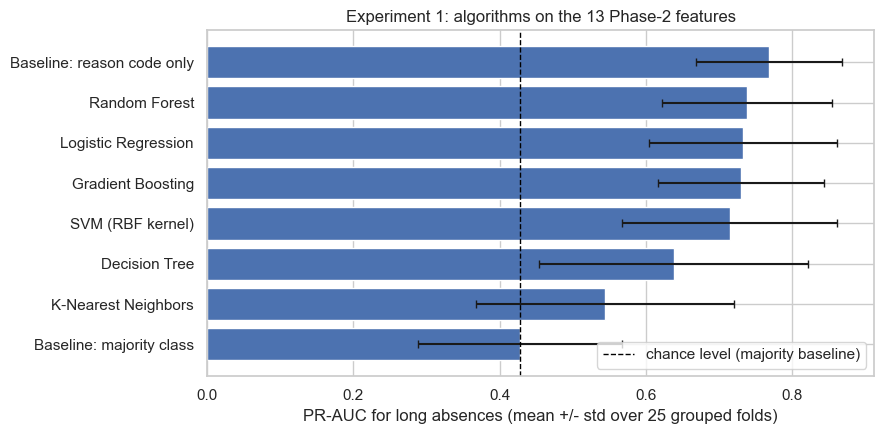

In [4]:
means = mean_table(exp1).sort_values("pr_auc")
stds = pd.DataFrame({n: r[["pr_auc"]].std() for n, r in exp1.items()}).T.loc[means.index]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(means.index, means["pr_auc"], xerr=stds["pr_auc"], color="#4C72B0", capsize=3)
CHANCE = exp1["Baseline: majority class"].pr_auc.mean()   # PR-AUC of a model with no skill
ax.axvline(CHANCE, color="black", ls="--", lw=1, label="chance level (majority baseline)")
ax.set_xlabel("PR-AUC for long absences (mean +/- std over 25 grouped folds)")
ax.set_title("Experiment 1: algorithms on the 13 Phase-2 features")
ax.legend(loc="lower right")
save_fig("10_exp1_model_comparison")

**Interpretation.**
* Every real model beats the majority baseline (PR-AUC 0.427), so the data does contain signal.
* **Surprise: the "reason code only" baseline (PR-AUC 0.768, F1 0.793, accuracy 0.819) beats every model that sees all 13 features.** The best full-feature model, Random Forest, scores 0.738.
* KNN is clearly weakest (PR-AUC 0.542, recall 0.488). The Decision Tree has the next-lowest ranking quality (0.638) despite decent recall.
* Fold-to-fold standard deviations are about 0.10-0.18, so differences of a few hundredths between models are within noise.

Why would extra information make models *worse*? The next two experiments answer that.

<a id='5'></a>
## 5. Experiment 2: random vs grouped validation

,PR-AUC grouped (new employees),PR-AUC random (seen employees),F1 grouped,F1 random,PR-AUC inflation
model,,,,,
Baseline: reason code only,0.768,0.788,0.793,0.800,0.019
Logistic Regression,0.732,0.811,0.706,0.780,0.078
Decision Tree,0.638,0.718,0.730,0.816,0.081
Random Forest,0.738,0.853,0.722,0.767,0.115
SVM (RBF kernel),0.714,0.839,0.623,0.761,0.125
K-Nearest Neighbors,0.544,0.724,0.404,0.616,0.180
Gradient Boosting,0.729,0.824,0.734,0.800,0.095


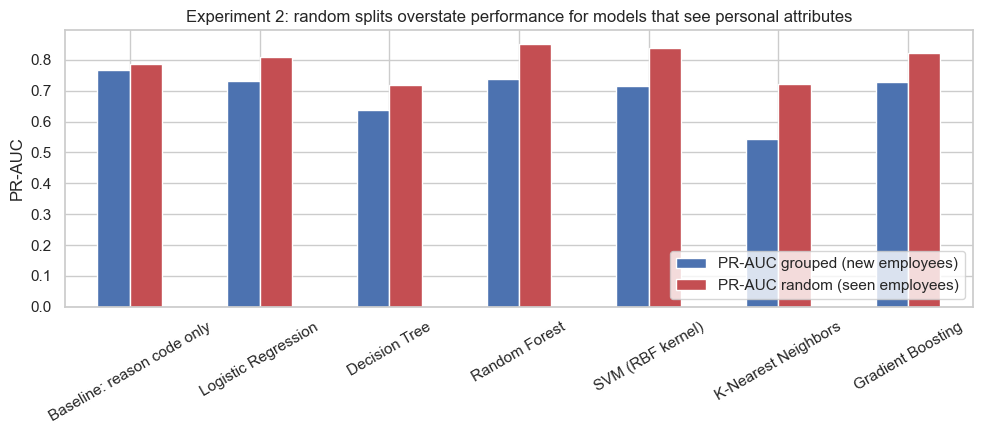

In [5]:
# Experiment 2: the same models scored with RANDOM row-level folds instead of employee-grouped folds
names2 = ["Baseline: reason code only", "Logistic Regression", "Decision Tree", "Random Forest",
          "SVM (RBF kernel)", "K-Nearest Neighbors", "Gradient Boosting"]
rows = []
for name in names2:
    random_cv = cross_validate(models_full[name], X_full, y_train, groups, grouped=False, seeds=SEEDS)
    rows.append({"model": name,
                 "PR-AUC grouped (new employees)": exp1[name].pr_auc.mean(),
                 "PR-AUC random (seen employees)": random_cv.pr_auc.mean(),
                 "F1 grouped": exp1[name].f1.mean(), "F1 random": random_cv.f1.mean()})
table2 = pd.DataFrame(rows).set_index("model")
table2["PR-AUC inflation"] = table2["PR-AUC random (seen employees)"] - table2["PR-AUC grouped (new employees)"]
table2.round(3).to_csv(TABLES_DIR / "exp2_random_vs_grouped.csv")
display(table2.round(3))

ax = table2[["PR-AUC grouped (new employees)", "PR-AUC random (seen employees)"]].plot.bar(
    figsize=(10, 4.5), color=["#4C72B0", "#C44E52"], rot=30)
ax.set_ylabel("PR-AUC"); ax.set_xlabel("")
ax.set_title("Experiment 2: random splits overstate performance for models that see personal attributes")
ax.legend(loc="lower right")
save_fig("11_exp2_random_vs_grouped")

**Interpretation - the employee-fingerprint effect.** With random row-level folds, an employee's other rows sit in the training data, and a flexible model recognises them from their personal attributes (age, distance, BMI, ...). The more flexible the model, the bigger the flattery:

* KNN: +0.189 PR-AUC, SVM +0.125, Random Forest +0.115, Gradient Boosting +0.095, Decision Tree +0.081, Logistic Regression +0.078.
* The reason-only baseline barely changes (+0.019) because it has no personal attributes to memorise.

A random split would have made Random Forest look like it scores 0.853, when the honest figure for a new employee is 0.738. This justifies the employee-grouped design from Phase 2.

<a id='6'></a>
## 6. Experiment 3: which features actually help?

In [6]:
# Experiment 3: which GROUPS of features actually help? (feature-set ablation)
personal = [config.TRANSPORT_EXPENSE, config.DISTANCE, config.SERVICE_TIME, config.AGE,
            config.EDUCATION, config.SON, config.PET, config.BMI]
calendar = [config.MONTH, config.DAY_OF_WEEK]
smoke_drink = config.BINARY_FEATURES

feature_sets = {
    "Reason only":               dict(categorical=[config.REASON], binary=[], numeric=[]),
    "Reason + month/day":        dict(categorical=[config.REASON] + calendar, binary=[], numeric=[]),
    "Reason + personal":         dict(categorical=[config.REASON], binary=smoke_drink, numeric=personal),
    "Full (13 Phase-2 features)": dict(),
    "Full + period features":    dict(numeric=config.NUMERIC_FEATURES + config.PERIOD_FEATURES),
    "No reason (month/day + personal)": dict(categorical=calendar, binary=smoke_drink, numeric=personal),
    "Personal attributes only":  dict(categorical=[], binary=smoke_drink, numeric=personal),
}
ablation_models = {
    "Logistic Regression": lambda: LogisticRegression(max_iter=1000),
    "Random Forest": lambda: RandomForestClassifier(n_estimators=150, min_samples_leaf=3,
                                                    random_state=config.RANDOM_STATE, n_jobs=1),
}

rows = []
for set_name, kw in feature_sets.items():
    cols = (kw.get("categorical", config.CATEGORICAL_FEATURES) + kw.get("binary", config.BINARY_FEATURES)
            + kw.get("numeric", config.NUMERIC_FEATURES))
    for model_name, make_clf in ablation_models.items():
        pipe = make_pipeline(make_clf(), build_preprocessor(**kw))
        grouped_cv = cross_validate(pipe, train_df[cols], y_train, groups, grouped=True, seeds=SEEDS)
        random_cv = cross_validate(pipe, train_df[cols], y_train, groups, grouped=False, seeds=SEEDS)
        rows.append({"feature set": set_name, "model": model_name,
                     "PR-AUC grouped": grouped_cv.pr_auc.mean(), "F1 grouped": grouped_cv.f1.mean(),
                     "recall grouped": grouped_cv.recall.mean(),
                     "PR-AUC random": random_cv.pr_auc.mean()})
table3 = pd.DataFrame(rows).set_index(["feature set", "model"])
table3.round(3).to_csv(TABLES_DIR / "exp3_feature_set_ablation.csv")
display(table3.round(3))

PR-AUC grouped  \
feature set                      model                                 
Reason only                      Logistic Regression           0.768   
                                 Random Forest                 0.764   
Reason + month/day               Logistic Regression           0.764   
                                 Random Forest                 0.781   
Reason + personal                Logistic Regression           0.746   
                                 Random Forest                 0.726   
Full (13 Phase-2 features)       Logistic Regression           0.732   
                                 Random Forest                 0.737   
Full + period features           Logistic Regression           0.736   
                                 Random Forest                 0.734   
No reason (month/day + personal) Logistic Regression           0.487   
                                 Random Forest                 0.500   
Personal attributes only         Logistic Regression           0.459   
                                 Random Forest                 0.454   

                                                      F1 grouped  \
feature set                      model                             
Reason only                      Logistic Regression       0.793   
                                 Random Forest             0.788   
Reason + month/day               Logistic Regression       0.775   
                                 Random Forest             0.788   
Reason + personal                Logistic Regression       0.728   
                                 Random Forest             0.754   
Full (13 Phase-2 features)       Logistic Regression       0.706   
                                 Random Forest             0.722   
Full + period features           Logistic Regression       0.705   
                                 Random Forest             0.706   
No reason (month/day + personal) Logistic Regression       0.370   
                                 Random Forest             0.434   
Personal attributes only         Logistic Regression       0.324   
                                 Random Forest             0.423   

                                                      recall grouped  \
feature set                      model                                 
Reason only                      Logistic Regression           0.869   
                                 Random Forest                 0.853   
Reason + month/day               Logistic Regression           0.824   
                                 Random Forest                 0.845   
Reason + personal                Logistic Regression           0.769   
                                 Random Forest                 0.874   
Full (13 Phase-2 features)       Logistic Regression           0.739   
                                 Random Forest                 0.837   
Full + period features           Logistic Regression           0.736   
                                 Random Forest                 0.817   
No reason (month/day + personal) Logistic Regression           0.427   
                                 Random Forest                 0.572   
Personal attributes only         Logistic Regression           0.372   
                                 Random Forest                 0.578   

                                                      PR-AUC random  
feature set                      model                               
Reason only                      Logistic Regression          0.788  
                                 Random Forest                0.782  
Reason + month/day               Logistic Regression          0.777  
                                 Random Forest                0.805  
Reason + personal                Logistic Regression          0.828  
                                 Random Forest                0.853  
Full (13 Phase-2 features)       Logistic Regression          0.811  
                             

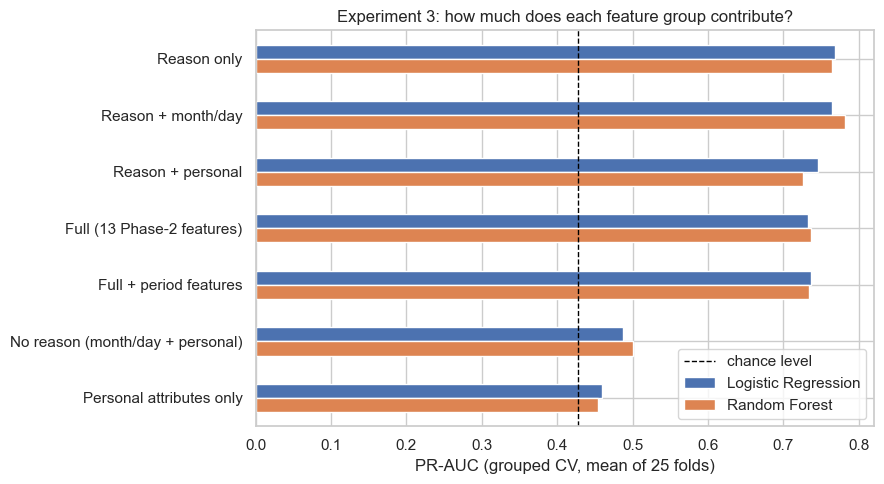

In [7]:
plot_df = table3.reset_index().pivot(index="feature set", columns="model", values="PR-AUC grouped").loc[list(feature_sets)]
ax = plot_df.plot.barh(figsize=(9, 5), color=["#4C72B0", "#DD8452"])
ax.axvline(CHANCE, color="black", ls="--", lw=1, label="chance level")
ax.legend(loc="lower right")
ax.invert_yaxis(); ax.set_xlabel("PR-AUC (grouped CV, mean of 25 folds)"); ax.set_ylabel("")
ax.set_title("Experiment 3: how much does each feature group contribute?")
save_fig("12_exp3_feature_ablation")

**Interpretation.**
* **Reason for absence carries almost all of the signal.** Removing it drops PR-AUC to 0.487 (LR) and 0.500 (RF), only slightly above the 0.427 chance level.
* **Personal attributes alone** (age, BMI, distance, children, ...) score 0.458 and 0.454, which is essentially chance for a new employee. Under random folds the same models score 0.587 and 0.664, which is pure memorisation.
* **Adding personal attributes to Reason makes grouped results worse** (LR 0.768 to 0.746; RF 0.764 to 0.726) while making random-fold results better (0.828, 0.853). That gap is the fingerprint again.
* **Month and day-of-week add little:** Random Forest improves slightly (0.764 to 0.781), Logistic Regression does not (0.768 to 0.764). These differences are inside the noise.
* **Period features (Workload, Hit target) do not help:** LR 0.732 to 0.736, RF 0.737 to 0.734. The Phase 2 decision to leave them out is confirmed by evidence.

**Decision.** Carry forward the reduced feature set **Reason + Month + Day-of-week** (3 inputs). It is as good as or better than every larger set under honest validation, it is easier to explain, and it means the app will not need personal or health-related attributes such as BMI or smoking status.

<a id='7'></a>
## 7. Experiment 4: what if the rule rows had been kept?

In [8]:
# Experiment 4: what would have happened if we had NOT excluded the 43 rule rows (Reason=0 / Disciplinary=1)?
with_rule_rows = add_target(raw)
with_rule_rows = with_rule_rows[with_rule_rows[config.GROUP_COLUMN].isin(groups.unique())]   # training employees only
with_rule_rows = with_rule_rows.reset_index(drop=True)

rows = []
for label, data in [("rule rows EXCLUDED (our dataset)", train_df), ("rule rows INCLUDED", with_rule_rows)]:
    for model_name, make_clf in ablation_models.items():
        pipe = make_pipeline(make_clf())
        r = cross_validate(pipe, data[config.FEATURE_COLUMNS], data[config.TARGET_COLUMN],
                           data[config.GROUP_COLUMN], grouped=True, seeds=SEEDS)
        rows.append({"dataset": label, "rows": len(data), "model": model_name,
                     "accuracy": r.accuracy.mean(), "PR-AUC": r.pr_auc.mean(), "F1": r.f1.mean()})
table4 = pd.DataFrame(rows).set_index(["dataset", "model"])
table4.round(3).to_csv(TABLES_DIR / "exp4_rule_rows_leakage_demo.csv")
display(table4.round(3))

rows  accuracy  PR-AUC  \
dataset                          model                                         
rule rows EXCLUDED (our dataset) Logistic Regression   575     0.755   0.732   
                                 Random Forest         575     0.741   0.737   
rule rows INCLUDED               Logistic Regression   608     0.775   0.711   
                                 Random Forest         608     0.779   0.736   

                                                         F1  
dataset                          model                       
rule rows EXCLUDED (our dataset) Logistic Regression  0.706  
                                 Random Forest        0.722  
rule rows INCLUDED               Logistic Regression  0.709  
                                 Random Forest        0.720

**Interpretation.** Keeping the rule rows (Reason = 0 or Disciplinary failure = 1, always 0 hours) adds 33 easy "short" examples to the training employees. Accuracy is flattered by about 2 points for Logistic Regression (0.755 to 0.775) and about 4 points for Random Forest (0.741 to 0.779), while PR-AUC does not improve (0.732 to 0.711 and 0.737 to 0.736). This is another reason to prefer PR-AUC over accuracy. The effect is modest because these rows are only about 5% of the data; the main reason to exclude them is that they are not genuine prediction targets, and the app will treat them as a documented rule instead.

<a id='8'></a>
## 8. Experiment 5: all algorithms on the reduced feature set

In [9]:
# Experiment 5: all algorithms again, on the reduced feature set suggested by Experiments 2-3
reduced_kwargs = dict(categorical=[config.REASON, config.MONTH, config.DAY_OF_WEEK], binary=[], numeric=[])
reduced_cols = reduced_kwargs["categorical"]
X_reduced = train_df[reduced_cols]

models_reduced = get_candidate_models(feature_kwargs=reduced_kwargs)
exp5 = {name: cross_validate(pipe, X_reduced, y_train, groups, grouped=True, seeds=SEEDS)
        for name, pipe in models_reduced.items()}

table5 = pd.DataFrame({name: summarize(r) for name, r in exp5.items()}).T
table5.to_csv(TABLES_DIR / "exp5_reduced_features_grouped_cv.csv")
display(table5)

,pr_auc,roc_auc,recall,precision,f1,balanced_acc,accuracy
Baseline: majority class,0.427 ± 0.139,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.573 ± 0.139
Baseline: reason code only,0.768 ± 0.100,0.859 ± 0.051,0.869 ± 0.070,0.739 ± 0.106,0.793 ± 0.063,0.824 ± 0.053,0.819 ± 0.048
Logistic Regression,0.764 ± 0.105,0.853 ± 0.051,0.824 ± 0.077,0.745 ± 0.103,0.775 ± 0.056,0.809 ± 0.045,0.808 ± 0.043
Decision Tree,0.721 ± 0.105,0.846 ± 0.058,0.918 ± 0.052,0.738 ± 0.101,0.814 ± 0.069,0.841 ± 0.055,0.835 ± 0.054
Random Forest,0.781 ± 0.101,0.865 ± 0.051,0.843 ± 0.067,0.754 ± 0.108,0.789 ± 0.058,0.821 ± 0.049,0.819 ± 0.047
SVM (RBF kernel),0.799 ± 0.107,0.869 ± 0.048,0.854 ± 0.068,0.750 ± 0.105,0.793 ± 0.061,0.823 ± 0.053,0.821 ± 0.049
K-Nearest Neighbors,0.731 ± 0.102,0.830 ± 0.052,0.592 ± 0.128,0.736 ± 0.116,0.639 ± 0.075,0.721 ± 0.061,0.726 ± 0.093
Gradient Boosting,0.771 ± 0.105,0.862 ± 0.050,0.857 ± 0.072,0.743 ± 0.108,0.789 ± 0.065,0.823 ± 0.048,0.818 ± 0.047


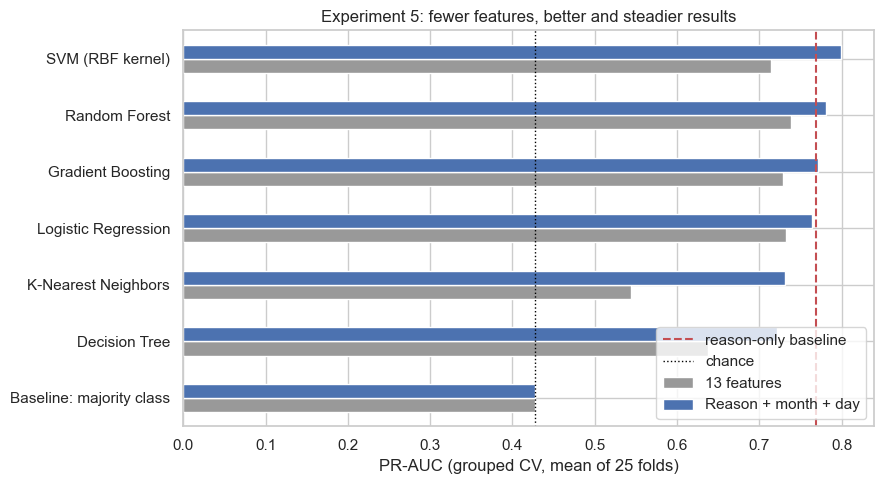

In [10]:
m1 = mean_table(exp1)["pr_auc"].rename("13 features")
m5 = mean_table(exp5)["pr_auc"].rename("Reason + month + day")
cmp = pd.concat([m1, m5], axis=1).drop(index=["Baseline: reason code only"]).sort_values("Reason + month + day")
ax = cmp.plot.barh(figsize=(9, 5), color=["#999999", "#4C72B0"])
ax.axvline(exp5["Baseline: reason code only"].pr_auc.mean(), color="#C44E52", ls="--", lw=1.5, label="reason-only baseline")
ax.axvline(CHANCE, color="black", ls=":", lw=1, label="chance")
ax.set_xlabel("PR-AUC (grouped CV, mean of 25 folds)"); ax.set_ylabel("")
ax.set_title("Experiment 5: fewer features, better and steadier results")
ax.legend(loc="lower right")
save_fig("13_exp5_reduced_features")

**Interpretation.**
* Every algorithm improves or holds steady with the reduced features, and the spread between models shrinks: SVM 0.799, Random Forest 0.781, Gradient Boosting 0.771, Logistic Regression 0.764, KNN 0.739, Decision Tree 0.721. The reason-only baseline is 0.768.
* **Decision Tree is a good example of why one metric is not enough.** It has the lowest PR-AUC (0.721) but the highest recall (0.918) and F1 (0.814) at the default 0.5 threshold, because its few leaves give coarse probabilities that happen to cross 0.5 often. Ranking quality and a single threshold's behaviour are different things.
* KNN remains weakest on recall (0.596).
* The top four models are within about 0.04 PR-AUC of each other, while fold-to-fold standard deviation is about 0.10. **The choice of algorithm matters much less than the choice of inputs.**

<a id='9'></a>
## 9. Experiment 6: hyperparameter tuning (nested cross-validation)

In [11]:
# Experiment 6: hyperparameter tuning with NESTED grouped CV (small grids: only 27 employees to learn from)
tuning_setup = {
    "Logistic Regression": (LogisticRegression(max_iter=1000), {"model__C": [0.01, 0.1, 1, 10]}),
    "Decision Tree": (models_reduced["Decision Tree"].named_steps["model"],
                      {"model__max_depth": [2, 3, 4, 6], "model__min_samples_leaf": [5, 10, 20]}),
    "Random Forest": (RandomForestClassifier(n_estimators=100, random_state=config.RANDOM_STATE, n_jobs=1),
                      {"model__max_depth": [3, 5], "model__min_samples_leaf": [5, 15]}),
    "SVM (RBF kernel)": (models_reduced["SVM (RBF kernel)"].named_steps["model"],
                         {"model__C": [0.1, 1, 10], "model__gamma": ["scale", 0.1]}),
    "K-Nearest Neighbors": (models_reduced["K-Nearest Neighbors"].named_steps["model"],
                            {"model__n_neighbors": [5, 15, 31, 51]}),
    "Gradient Boosting": (GradientBoostingClassifier(learning_rate=0.1, random_state=config.RANDOM_STATE),
                          {"model__max_depth": [1, 2], "model__n_estimators": [50, 100]}),
}
TUNING_SEEDS = (0, 1)

rows, chosen_params = [], {}
for name, (clf, grid) in tuning_setup.items():
    tuned_folds, chosen = nested_cv_tuning(make_pipeline(clf, build_preprocessor(**reduced_kwargs)),
                                           grid, X_reduced, y_train, groups, seeds=TUNING_SEEDS)
    untuned_folds = exp5[name][exp5[name].seed.isin(TUNING_SEEDS)]       # same seeds -> same outer folds
    rows.append({"model": name,
                 "PR-AUC untuned": untuned_folds.pr_auc.mean(), "PR-AUC tuned (nested)": tuned_folds.pr_auc.mean(),
                 "F1 untuned": untuned_folds.f1.mean(), "F1 tuned (nested)": tuned_folds.f1.mean()})
    chosen_params[name] = chosen.astype(str).apply(lambda r: ", ".join(f"{k}={v}" for k, v in r.items()), axis=1) \
                                .value_counts().head(2).to_dict()
table6 = pd.DataFrame(rows).set_index("model")
table6["PR-AUC change"] = table6["PR-AUC tuned (nested)"] - table6["PR-AUC untuned"]
table6.round(3).to_csv(TABLES_DIR / "exp6_tuning_nested_cv.csv")
display(table6.round(3))
print("Most frequently chosen settings across outer folds:")
for name, picks in chosen_params.items():
    print(f"  {name}: {picks}")

,PR-AUC untuned,PR-AUC tuned (nested),F1 untuned,F1 tuned (nested),PR-AUC change
model,,,,,
Logistic Regression,0.774,0.762,0.776,0.668,-0.013
Decision Tree,0.730,0.708,0.818,0.765,-0.022
Random Forest,0.796,0.786,0.796,0.576,-0.010
SVM (RBF kernel),0.816,0.798,0.797,0.715,-0.017
K-Nearest Neighbors,0.748,0.728,0.640,0.624,-0.020
Gradient Boosting,0.781,0.765,0.798,0.800,-0.015


Most frequently chosen settings across outer folds:
  Logistic Regression: {'C=0.1': 3, 'C=1.0': 3}
  Decision Tree: {'max_depth=6, min_samples_leaf=10': 5, 'max_depth=6, min_samples_leaf=20': 2}
  Random Forest: {'max_depth=3, min_samples_leaf=5': 5, 'max_depth=5, min_samples_leaf=5': 4}
  SVM (RBF kernel): {'C=1.0, gamma=scale': 6, 'C=0.1, gamma=0.1': 1}
  K-Nearest Neighbors: {'n_neighbors=31': 3, 'n_neighbors=51': 3}
  Gradient Boosting: {'max_depth=2, n_estimators=100': 5, 'max_depth=2, n_estimators=50': 3}


**Interpretation.** Tuning did **not** help: the honest nested estimate is lower than the untuned default for every algorithm (PR-AUC changes between -0.010 and -0.022). Note that the 'untuned' column here uses only seeds 0-1 so that it matches the tuned run's outer folds; it therefore differs slightly from the 25-fold figures in Experiment 5. With only 27 employees, the inner folds are small, so the settings that look best there are partly chance and do not carry over to the outer folds. The chosen settings also varied between folds (for example Logistic Regression alternated between `C=0.1` and `C=1`), and the SVM kept its default settings in 6 of 10 folds. We therefore keep the simple, fixed, documented settings and do not claim any benefit from tuning. (F1 at 0.5 fell for several models because tuning optimises PR-AUC, which does not control where the 0.5 cut-off lands.)

The grids here were deliberately small. This is an honest negative result, not proof that no tuning could help.

<a id='10'></a>
## 10. Experiment 7: confirmation on fresh folds

In [12]:
# Experiment 7: confirmation on FRESH seeds (new random fold assignments never used for any decision above)
CONFIRM_SEEDS = (10, 11, 12, 13, 14)
contenders = {
    "Reason-only baseline (LR)":              (models_reduced["Baseline: reason code only"], X_reduced),
    "Logistic Regression (reason+month+day)": (models_reduced["Logistic Regression"], X_reduced),
    "Random Forest (reason+month+day)":       (models_reduced["Random Forest"], X_reduced),
    "SVM (reason+month+day)":                 (models_reduced["SVM (RBF kernel)"], X_reduced),
    "Gradient Boosting (reason+month+day)":   (models_reduced["Gradient Boosting"], X_reduced),
    "Random Forest (13 features)":            (models_full["Random Forest"], X_full),
}
exp7 = {name: cross_validate(pipe, X, y_train, groups, grouped=True, seeds=CONFIRM_SEEDS)
        for name, (pipe, X) in contenders.items()}
table7 = pd.DataFrame({name: summarize(r) for name, r in exp7.items()}).T
table7.to_csv(TABLES_DIR / "exp7_confirmation_fresh_seeds.csv")
display(table7)

reference = "Reason-only baseline (LR)"
paired = pd.DataFrame({name: paired_difference(r, exp7[reference]) for name, r in exp7.items() if name != reference}).T
paired = paired[["mean_diff", "std_diff", "A_wins_share", "n_folds"]].rename(
    columns={"mean_diff": "PR-AUC difference vs reason-only", "std_diff": "std of difference",
             "A_wins_share": "share of folds where model wins"})
paired.round(3).to_csv(TABLES_DIR / "exp7_paired_vs_reason_only.csv")
display(paired.round(3))

,pr_auc,roc_auc,recall,precision,f1,balanced_acc,accuracy
Reason-only baseline (LR),0.771 ± 0.109,0.860 ± 0.053,0.873 ± 0.064,0.744 ± 0.115,0.797 ± 0.072,0.826 ± 0.049,0.823 ± 0.053
Logistic Regression (reason+month+day),0.766 ± 0.109,0.854 ± 0.054,0.842 ± 0.068,0.744 ± 0.114,0.783 ± 0.065,0.815 ± 0.048,0.812 ± 0.052
Random Forest (reason+month+day),0.789 ± 0.094,0.868 ± 0.051,0.855 ± 0.061,0.748 ± 0.112,0.791 ± 0.065,0.822 ± 0.041,0.820 ± 0.047
SVM (reason+month+day),0.807 ± 0.086,0.871 ± 0.045,0.858 ± 0.050,0.749 ± 0.113,0.794 ± 0.064,0.823 ± 0.042,0.821 ± 0.050
Gradient Boosting (reason+month+day),0.766 ± 0.110,0.862 ± 0.050,0.857 ± 0.068,0.742 ± 0.116,0.789 ± 0.070,0.820 ± 0.046,0.817 ± 0.050
Random Forest (13 features),0.744 ± 0.107,0.828 ± 0.059,0.849 ± 0.100,0.695 ± 0.133,0.754 ± 0.087,0.791 ± 0.052,0.783 ± 0.047


,PR-AUC difference vs reason-only,std of difference,share of folds where model wins,n_folds
Logistic Regression (reason+month+day),-0.005,0.031,0.32,25.0
Random Forest (reason+month+day),0.018,0.030,0.76,25.0
SVM (reason+month+day),0.036,0.053,0.80,25.0
Gradient Boosting (reason+month+day),-0.005,0.021,0.36,25.0
Random Forest (13 features),-0.027,0.061,0.40,25.0


**Why this step exists.** Experiments 1-6 were used to make choices (feature set, shortlist), which can make the winners look slightly better than they really are. Here the shortlist is re-scored on **new random fold assignments (seeds 10-14) that played no part in any decision**.

**Interpretation.**
* **SVM** (0.807) and **Random Forest** (0.789) on Reason + Month + Day remain the highest, ahead of the reason-only baseline (0.771). Logistic Regression and Gradient Boosting (0.766 each) are no better than the baseline.
* Paired against the reason-only baseline on identical folds: SVM +0.036 (better in 80% of folds), Random Forest +0.018 (76%), Logistic Regression and Gradient Boosting -0.005. The standard deviation of the per-fold difference (0.02-0.06) is as large as the gains for most models.
* Random Forest on all 13 features is 0.027 *worse* than the baseline on these folds, confirming that the extra attributes hurt.
* Caution: "share of folds won" counts repeated, overlapping folds of the same 27 employees, so it overstates how certain we can be. The honest summary is that SVM and Random Forest show a **small, consistent advantage of a few hundredths of PR-AUC**, which is too small to be proven with this little data.

<a id='11'></a>
## 11. Summary, trade-offs and decisions

| Finding (all verified above) | Consequence |
|---|---|
| Random row-level splits overstate performance by up to 0.19 PR-AUC | All model selection stays employee-grouped |
| Reason for absence provides nearly all the signal; personal attributes behave as employee fingerprints and hurt for new employees | **Model inputs reduced to Reason + Month + Day-of-week** |
| Period features add nothing | Stay excluded |
| A trivial reason-only model scores PR-AUC 0.768 / F1 0.793 | It is the benchmark every candidate must beat, and it will be shown honestly in the app |
| Tuning did not improve any model under nested CV | Keep fixed default settings |
| Top models differ by only about 0.02-0.04 PR-AUC, with fold std about 0.10 | Final choice should weigh interpretability, probability quality and simplicity, not a tiny score gap |

**Realistic expectations.** On the confirmation folds the best models reach PR-AUC about 0.79-0.81, recall about 0.86 and precision about 0.75, with accuracy about 0.82. The model is useful mainly because the reason code is informative; it is **not** a precise individual-level forecaster, and results from 27 employees will be noisy.

**Limitations to carry forward.** Only 27 training employees; per-fold variation is large; the reason-code meanings are not documented in the dataset; correlations are not causes.